# M4 Exploratory Data Analysis — NYC 311 and Open-Meteo

**Lifecycle stage:** EXPLORE  
**Analysis window:** 12 October 2025–9 October 2026 (363 complete local dates)  
**Timezone:** `America/New_York`  
**Database:** `data/nyc311_weather.db`

This notebook investigates whether NYC 311 request volume and complaint mix vary by borough, local time, calendar period, and weather conditions. It compares raw and cleaned counts, describes the shape of daily volume, checks coverage and quality flags, compares local and UTC clock profiles, explores snow-related relationships, and estimates a weekday/weekend difference with a week-block bootstrap.

**Rebuild before running:** from a fresh clone with the complete landed raw inputs, run `python3 src/load.py`, `python3 src/clean.py`, and `python3 src/validate.py`. Then start Jupyter from the project root (or `notebooks/`) and use **Restart Kernel and Run All**. The notebook opens SQLite in read-only mode; it does not alter the database. Save the executed outputs when committing it.

**Interpretation rules:** `UNSPECIFIED` is excluded from five-borough comparisons; the partial 10 October 2026 request date is excluded; local dates/hours are used for human activity; UTC profiles use only unambiguous `ok` timestamps; unusual values are investigated rather than automatically removed; associations are not interpreted as causal effects.

In [31]:
# 1. Parameters and imports — edit this cell to change the analysis window or filters.
from pathlib import Path
from datetime import date, datetime, time, timedelta, timezone
from zoneinfo import ZoneInfo
from collections import Counter, defaultdict
from statistics import mean, median, stdev
import hashlib
import math
import random
import sqlite3
import sys

import matplotlib.pyplot as plt

PROJECT_CANDIDATES = [Path.cwd(), Path.cwd().parent]
PROJECT_ROOT = next(
    (p.resolve() for p in PROJECT_CANDIDATES
     if (p / "data" / "nyc311_weather.db").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate data/nyc311_weather.db. Start Jupyter from the "
        "project root or its notebooks/ directory."
    )

DB_PATH = PROJECT_ROOT / "data" / "nyc311_weather.db"
FIGURES_DIR = PROJECT_ROOT / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

START_DATE = date(2025, 10, 12)
END_DATE = date(2026, 10, 9)  # last complete day; 10 October is partial
TIMEZONE_NAME = "America/New_York"
LOCAL_TZ = ZoneInfo(TIMEZONE_NAME)
BOROUGH_IDS = (1, 2, 3, 4, 5)
BOROUGH_NAMES = {
    1: "Bronx",
    2: "Manhattan",
    3: "Brooklyn",
    4: "Queens",
    5: "Staten Island",
}
BOROUGH_ORDER = ["Bronx", "Brooklyn", "Manhattan", "Queens", "Staten Island"]
COVERAGE_THRESHOLD = 0.90
HISTOGRAM_BIN_WIDTHS = (250, 500, 1000)
SELECTED_HISTOGRAM_BIN_WIDTH = 500
BOOTSTRAP_REPETITIONS = 20_000
BOOTSTRAP_SEED = 20261115
SNOW_CODES = {71, 73, 75, 77, 85, 86}
STORM_WINDOWS = (
    (date(2026, 1, 25), date(2026, 1, 31)),
    (date(2026, 2, 21), date(2026, 2, 28)),
)

EXPECTED_DATES = []
_d = START_DATE
while _d <= END_DATE:
    EXPECTED_DATES.append(_d)
    _d += timedelta(days=1)
EXPECTED_DATE_STRINGS = [d.isoformat() for d in EXPECTED_DATES]

DB_STAT_BEFORE = (DB_PATH.stat().st_size, DB_PATH.stat().st_mtime_ns)
DB_URI = DB_PATH.resolve().as_uri() + "?mode=ro"
CON = sqlite3.connect(DB_URI, uri=True)
CON.row_factory = sqlite3.Row
CON.execute("PRAGMA query_only = ON")

print("Project root:", PROJECT_ROOT)
print("Database:", DB_PATH)
print("SQLite read-only:", CON.execute("PRAGMA query_only").fetchone()[0] == 1)
print("Analysis dates:", START_DATE, "through", END_DATE)
print("Expected local dates:", len(EXPECTED_DATES))

Project root: /home/seymanur/projects/nyc-311-weather-analysis
Database: /home/seymanur/projects/nyc-311-weather-analysis/data/nyc311_weather.db
SQLite read-only: True
Analysis dates: 2025-10-12 through 2026-10-09
Expected local dates: 363


## 2. Raw versus cleaned: does the key daily number change?

**Question:** Does the daily number of requests change between the M2 raw table and the M3 cleaned table when the same five-borough, full-day window is used?

**Filter and grain:** five named borough IDs (`1`–`5`); local date 2025-10-12 through 2026-10-09 inclusive; one row per borough × local date. The raw table uses the preserved source date string (`created_date_source`); the cleaned table uses `created_local_date`. Both queries use parameter placeholders.

In [32]:
raw_daily_rows = CON.execute(
    """
    SELECT borough_id,
           substr(created_date_source, 1, 10) AS local_date,
           COUNT(*) AS requests
    FROM service_requests
    WHERE borough_id IN (?, ?, ?, ?, ?)
      AND substr(created_date_source, 1, 10) >= ?
      AND substr(created_date_source, 1, 10) <= ?
    GROUP BY borough_id, substr(created_date_source, 1, 10)
    ORDER BY borough_id, local_date
    """,
    (*BOROUGH_IDS, START_DATE.isoformat(), END_DATE.isoformat()),
).fetchall()

clean_daily_rows = CON.execute(
    """
    SELECT borough_id,
           created_local_date AS local_date,
           COUNT(*) AS requests
    FROM service_requests_clean
    WHERE borough_id IN (?, ?, ?, ?, ?)
      AND created_local_date >= ?
      AND created_local_date <= ?
    GROUP BY borough_id, created_local_date
    ORDER BY borough_id, local_date
    """,
    (*BOROUGH_IDS, START_DATE.isoformat(), END_DATE.isoformat()),
).fetchall()

raw_daily = {(r["borough_id"], r["local_date"]): r["requests"] for r in raw_daily_rows}
clean_daily = {(r["borough_id"], r["local_date"]): r["requests"] for r in clean_daily_rows}
raw_total = sum(raw_daily.values())
clean_total = sum(clean_daily.values())
raw_vs_clean_differences = [
    (key, raw_daily.get(key, 0), clean_daily.get(key, 0))
    for key in sorted(set(raw_daily) | set(clean_daily))
    if raw_daily.get(key, 0) != clean_daily.get(key, 0)
]

print("RAW borough-day rows:", len(raw_daily_rows))
print("CLEAN borough-day rows:", len(clean_daily_rows))
print("RAW requests:", f"{raw_total:,}")
print("CLEAN requests:", f"{clean_total:,}")
print("RAW vs CLEAN borough-day mismatches:", len(raw_vs_clean_differences))
print("RAW daily mean:", round(raw_total / len(EXPECTED_DATES), 2))
print("CLEAN daily mean:", round(clean_total / len(EXPECTED_DATES), 2))
assert raw_total == clean_total, "Raw and cleaned request totals differ in the defined window."
assert not raw_vs_clean_differences, "At least one borough-day count differs between raw and clean."
assert len(clean_daily_rows) == len(BOROUGH_IDS) * len(EXPECTED_DATES)

print("\nBy borough:")
for borough_id in BOROUGH_IDS:
    raw_n = sum(v for (bid, _), v in raw_daily.items() if bid == borough_id)
    clean_n = sum(v for (bid, _), v in clean_daily.items() if bid == borough_id)
    print(BOROUGH_NAMES[borough_id], "raw=", f"{raw_n:,}", "clean=", f"{clean_n:,}")

RAW borough-day rows: 1815
CLEAN borough-day rows: 1815
RAW requests: 3,948,366
CLEAN requests: 3,948,366
RAW vs CLEAN borough-day mismatches: 0
RAW daily mean: 10877.04
CLEAN daily mean: 10877.04

By borough:
Bronx raw= 842,677 clean= 842,677
Manhattan raw= 768,279 clean= 768,279
Brooklyn raw= 1,212,672 clean= 1,212,672
Queens raw= 963,779 clean= 963,779
Staten Island raw= 160,959 clean= 160,959


## 3. Main analysis panel: daily requests by borough

**Question:** How does the daily number of 311 requests vary across the five named boroughs? The result grain is one borough × local date. Daily counts are built in SQL before visualisation; zero-count days are retained as explicit zeros, then checked separately from absent date rows.

In [33]:
request_daily_rows = CON.execute(
    """
    SELECT borough_id,
           created_local_date AS local_date,
           COUNT(*) AS requests,
           SUM(CASE WHEN complaint_type_id = (
               SELECT complaint_type_id
               FROM complaint_types
               WHERE complaint_type = ?
           ) THEN 1 ELSE 0 END) AS snow_ice_requests
    FROM service_requests_clean
    WHERE borough_id IN (?, ?, ?, ?, ?)
      AND created_local_date >= ?
      AND created_local_date <= ?
    GROUP BY borough_id, created_local_date
    ORDER BY borough_id, local_date
    """,
    ('SNOW OR ICE', *BOROUGH_IDS, START_DATE.isoformat(), END_DATE.isoformat()),
).fetchall()

request_by_borough_day = {
    bid: {d.isoformat(): {"requests": 0, "snow_ice": 0} for d in EXPECTED_DATES}
    for bid in BOROUGH_IDS
}
for row in request_daily_rows:
    request_by_borough_day[row["borough_id"]][row["local_date"]] = {
        "requests": int(row["requests"]),
        "snow_ice": int(row["snow_ice_requests"] or 0),
    }

assert len(request_daily_rows) == 5 * 363
assert all(
    request_by_borough_day[bid][d.isoformat()]["requests"] > 0
    for bid in BOROUGH_IDS for d in EXPECTED_DATES
), "A borough-day has no requests; investigate before interpreting it as zero."

borough_daily = {
    BOROUGH_NAMES[bid]: [
        request_by_borough_day[bid][d.isoformat()]["requests"]
        for d in EXPECTED_DATES
    ]
    for bid in BOROUGH_IDS
}
citywide_daily = [
    sum(request_by_borough_day[bid][d.isoformat()]["requests"] for bid in BOROUGH_IDS)
    for d in EXPECTED_DATES
]
snow_ice_share_by_borough_day = {
    (bid, d.isoformat()): (
        request_by_borough_day[bid][d.isoformat()]["snow_ice"]
        / request_by_borough_day[bid][d.isoformat()]["requests"]
    )
    for bid in BOROUGH_IDS for d in EXPECTED_DATES
}

# Nearest-rank percentiles: sorted_values[ceil(p*n)-1].
def nearest_rank(values, p):
    ordered = sorted(values)
    return ordered[max(0, math.ceil(p * len(ordered)) - 1)]

def skewness(values):
    avg = mean(values)
    m2 = sum((x - avg) ** 2 for x in values) / len(values)
    if m2 == 0:
        return float("nan")
    m3 = sum((x - avg) ** 3 for x in values) / len(values)
    return m3 / (m2 ** 1.5)

def describe_distribution(label, values):
    return {
        "group": label,
        "n": len(values),
        "mean": mean(values),
        "median": median(values),
        "std": stdev(values),
        "min": min(values),
        "q1": nearest_rank(values, 0.25),
        "q3": nearest_rank(values, 0.75),
        "p90": nearest_rank(values, 0.90),
        "p95": nearest_rank(values, 0.95),
        "max": max(values),
        "skewness": skewness(values),
    }

distribution_summaries = [describe_distribution("CITYWIDE", citywide_daily)]
distribution_summaries += [
    describe_distribution(name, borough_daily[name]) for name in BOROUGH_ORDER
]
print("group | n | mean | median | std | min | Q1 | Q3 | P90 | P95 | max | skewness")
for s in distribution_summaries:
    print(
        f"{s['group']} | {s['n']} | {s['mean']:.2f} | {s['median']:.2f} | "
        f"{s['std']:.2f} | {s['min']} | {s['q1']} | {s['q3']} | "
        f"{s['p90']} | {s['p95']} | {s['max']} | {s['skewness']:.3f}"
    )

citywide_total = sum(citywide_daily)
citywide_max_index = citywide_daily.index(max(citywide_daily))
citywide_min_index = citywide_daily.index(min(citywide_daily))
print("\nCitywide total:", f"{citywide_total:,}")
print("Citywide daily mean:", round(mean(citywide_daily), 2))
print("Maximum day:", EXPECTED_DATES[citywide_max_index], max(citywide_daily))
print("Minimum day:", EXPECTED_DATES[citywide_min_index], min(citywide_daily))

group | n | mean | median | std | min | Q1 | Q3 | P90 | P95 | max | skewness
CITYWIDE | 363 | 10877.04 | 10784.00 | 1631.48 | 6214 | 9998 | 11580 | 12360 | 13448 | 22796 | 1.861
Bronx | 363 | 2321.42 | 2136.00 | 655.10 | 1459 | 1951 | 2364 | 3286 | 3949 | 5232 | 1.980
Brooklyn | 363 | 3340.69 | 3330.00 | 547.97 | 1711 | 3003 | 3606 | 3894 | 4149 | 6314 | 0.968
Manhattan | 363 | 2116.47 | 2114.00 | 299.87 | 1124 | 1938 | 2262 | 2472 | 2563 | 3275 | 0.363
Queens | 363 | 2655.04 | 2636.00 | 391.15 | 1659 | 2435 | 2867 | 3076 | 3275 | 5108 | 1.134
Staten Island | 363 | 443.41 | 415.00 | 321.68 | 155 | 354 | 464 | 519 | 600 | 4698 | 10.496

Citywide total: 3,948,366
Citywide daily mean: 10877.04
Maximum day: 2026-02-24 22796
Minimum day: 2025-12-25 6214


## 4. Distribution figures: histogram sensitivity, borough comparison, and ECDF

Three histogram bin widths (250, 500, and 1,000 requests) are compared before choosing 500 as the main citywide display width. Borough histograms use a common 250-request bin width and shared axes. ECDFs show the full empirical distributions without relying on bin choices.

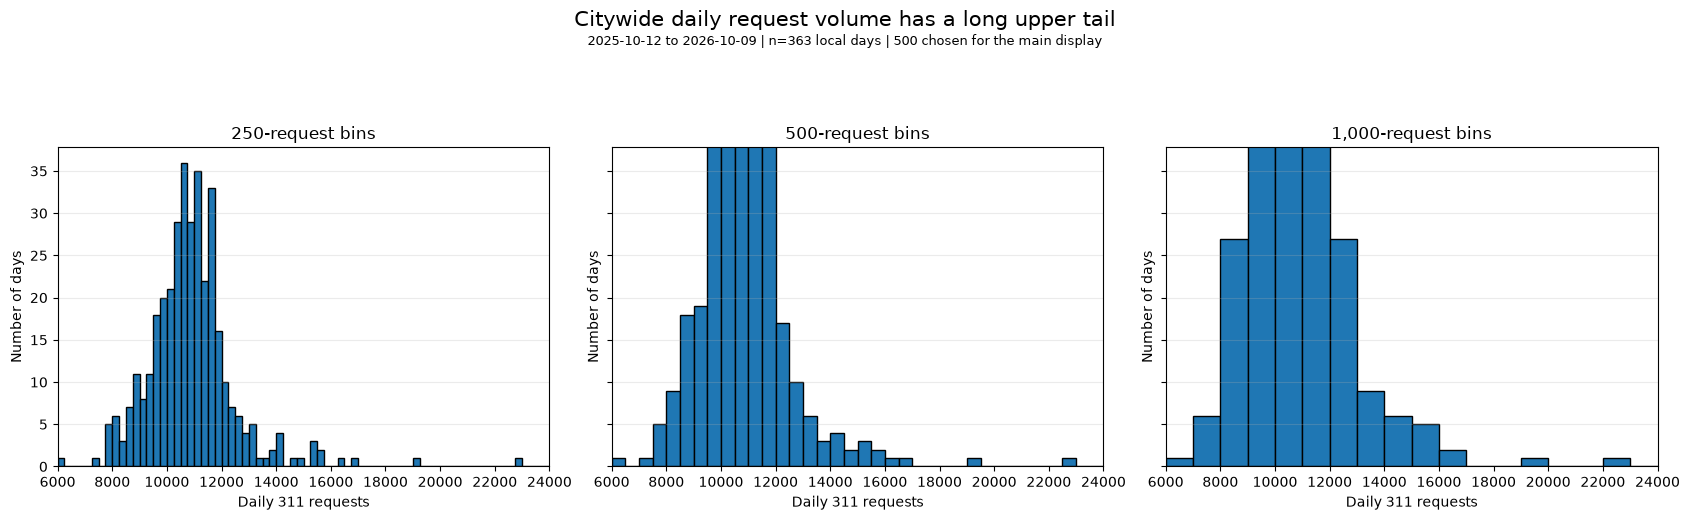

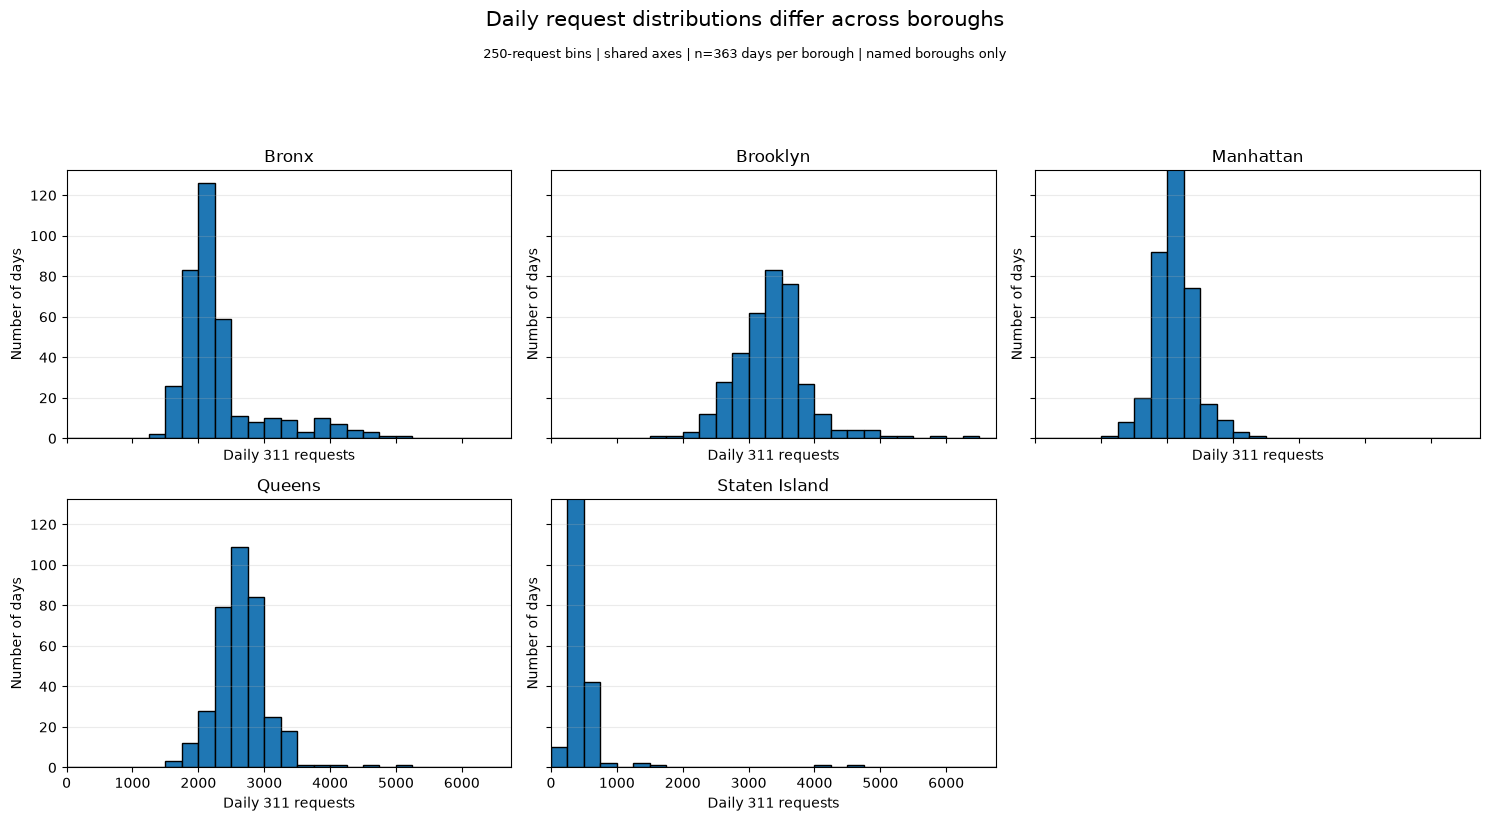

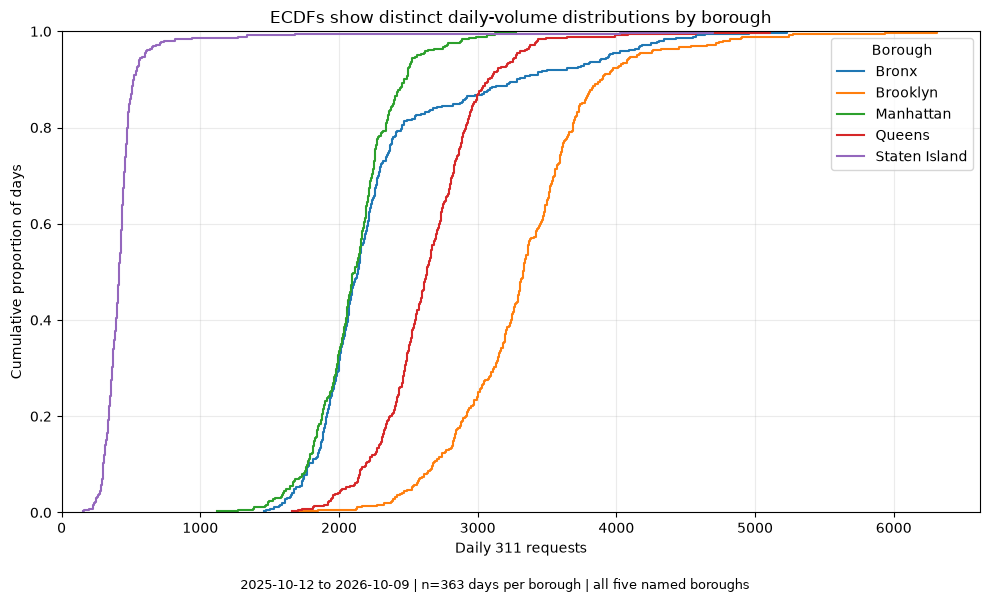

In [34]:
# Figure 1 — histogram bin-width sensitivity. Each panel uses the same x range.
fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharex=True, sharey=True)
for ax, width in zip(axes, HISTOGRAM_BIN_WIDTHS):
    bins = list(range(6000, 24001, width))
    ax.hist(citywide_daily, bins=bins, edgecolor="black")
    ax.set_title(f"{width:,}-request bins")
    ax.set_xlabel("Daily 311 requests")
    ax.set_ylabel("Number of days")
    ax.set_xlim(6000, 24000)
    ax.set_ylim(bottom=0)
    ax.grid(axis="y", alpha=0.25)
fig.suptitle("Citywide daily request volume has a long upper tail", fontsize=15, y=1.03)
fig.text(
    0.5, 0.96,
    f"{START_DATE} to {END_DATE} | n={len(citywide_daily)} local days | 500 chosen for the main display",
    ha="center", fontsize=9,
)
fig.tight_layout(rect=[0, 0, 1, 0.90])
fig.savefig(FIGURES_DIR / "daily_volume_histogram_sensitivity.png", dpi=180, bbox_inches="tight")
plt.show()

# Figure 2 — common-scale borough histograms.
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey=True)
axes = axes.flatten()
borough_bins = list(range(0, 6751, 250))
for ax, borough in zip(axes, BOROUGH_ORDER):
    ax.hist(borough_daily[borough], bins=borough_bins, edgecolor="black")
    ax.set_title(borough)
    ax.set_xlabel("Daily 311 requests")
    ax.set_ylabel("Number of days")
    ax.set_xlim(0, 6750)
    ax.set_ylim(bottom=0)
    ax.grid(axis="y", alpha=0.25)
axes[-1].axis("off")
fig.suptitle("Daily request distributions differ across boroughs", fontsize=15, y=1.02)
fig.text(0.5, 0.96, "250-request bins | shared axes | n=363 days per borough | named boroughs only", ha="center", fontsize=9)
fig.tight_layout(rect=[0, 0, 1, 0.91])
fig.savefig(FIGURES_DIR / "daily_volume_histogram_by_borough.png", dpi=180, bbox_inches="tight")
plt.show()

# Figure 3 — empirical cumulative distribution functions.
fig, ax = plt.subplots(figsize=(10, 6))
for borough in BOROUGH_ORDER:
    values = sorted(borough_daily[borough])
    y = [(i + 1) / len(values) for i in range(len(values))]
    ax.step(values, y, where="post", label=borough)
ax.set_title("ECDFs show distinct daily-volume distributions by borough")
ax.set_xlabel("Daily 311 requests")
ax.set_ylabel("Cumulative proportion of days")
ax.set_xlim(left=0)
ax.set_ylim(0, 1)
ax.grid(alpha=0.25)
ax.legend(title="Borough")
fig.text(0.5, 0.01, f"{START_DATE} to {END_DATE} | n=363 days per borough | all five named boroughs", ha="center", fontsize=9)
fig.tight_layout(rect=[0, 0.04, 1, 1])
fig.savefig(FIGURES_DIR / "daily_volume_ecdf_by_borough.png", dpi=180, bbox_inches="tight")
plt.show()

## 5. Coverage, denominators, and quality flags

**311 denominator:** one expected request-count observation for each of 363 local dates in each named borough.  
**Weather denominator:** expected local hours for each borough × local date. Expected hours are calculated from consecutive local midnights converted to UTC, so 23-hour and 25-hour DST days are handled explicitly.  
**Daily aggregation rule:** at least 90% of expected observations must pass the relevant field flag. `unusual_high` is kept as a distinct flag and tested as an alternative precipitation filter, not silently relabelled as `ok`.

In [35]:
WEATHER_SQL = """
SELECT wl.borough_id,
       w.observed_at_utc,
       w.temperature_2m_c, w.temperature_2m_c_flag,
       w.relative_humidity_2m_pct, w.relative_humidity_2m_pct_flag,
       w.precipitation_mm, w.precipitation_mm_flag,
       w.weather_code, w.weather_code_flag,
       w.wind_speed_10m_kmh, w.wind_speed_10m_kmh_flag,
       w.wind_direction_10m_degrees, w.wind_direction_10m_degrees_flag,
       w.cloud_cover_pct, w.cloud_cover_pct_flag
FROM weather_observations_clean AS w
JOIN weather_locations AS wl
  ON w.weather_location_id = wl.weather_location_id
WHERE wl.borough_id IN (?, ?, ?, ?, ?)
ORDER BY wl.borough_id, w.observed_at_utc
"""
weather_rows = CON.execute(WEATHER_SQL, BOROUGH_IDS).fetchall()

def expected_local_hours(day):
    start_local = datetime.combine(day, time.min, tzinfo=LOCAL_TZ)
    end_local = datetime.combine(day + timedelta(days=1), time.min, tzinfo=LOCAL_TZ)
    elapsed = end_local.astimezone(timezone.utc) - start_local.astimezone(timezone.utc)
    return int(elapsed.total_seconds() // 3600)

WEATHER_FIELDS = {
    "temperature": ("temperature_2m_c", "temperature_2m_c_flag"),
    "humidity": ("relative_humidity_2m_pct", "relative_humidity_2m_pct_flag"),
    "precipitation": ("precipitation_mm", "precipitation_mm_flag"),
    "weather_code": ("weather_code", "weather_code_flag"),
    "wind_speed": ("wind_speed_10m_kmh", "wind_speed_10m_kmh_flag"),
    "wind_direction": ("wind_direction_10m_degrees", "wind_direction_10m_degrees_flag"),
    "cloud_cover": ("cloud_cover_pct", "cloud_cover_pct_flag"),
}
weather_daily = {
    (bid, d.isoformat()): {
        "observed": 0,
        "flags": {name: Counter() for name in WEATHER_FIELDS},
        "valid_counts": Counter(),
        "precip_ok_sum": 0.0,
        "precip_inclusive_sum": 0.0,
        "precip_ok_count": 0,
        "precip_inclusive_count": 0,
        "snow_hours": 0,
        "temperature_ok_sum": 0.0,
    }
    for bid in BOROUGH_IDS for d in EXPECTED_DATES
}
weather_flag_totals = {
    (bid, field): Counter()
    for bid in BOROUGH_IDS for field in WEATHER_FIELDS
}
weather_local_exposure = Counter()
weather_utc_exposure = Counter()
weather_seen = set()
weather_duplicate_hours = 0
weather_outside_window = 0

for row in weather_rows:
    bid = row["borough_id"]
    utc_dt = datetime.fromisoformat(row["observed_at_utc"].replace("Z", "+00:00"))
    local_dt = utc_dt.astimezone(LOCAL_TZ)
    if not (START_DATE <= local_dt.date() <= END_DATE):
        weather_outside_window += 1
        continue
    day_key = local_dt.date().isoformat()
    item = weather_daily[(bid, day_key)]
    item["observed"] += 1
    weather_local_exposure[local_dt.hour] += 1
    weather_utc_exposure[utc_dt.hour] += 1
    pair = (bid, row["observed_at_utc"])
    if pair in weather_seen:
        weather_duplicate_hours += 1
    weather_seen.add(pair)

    for field, (value_col, flag_col) in WEATHER_FIELDS.items():
        value = row[value_col]
        flag = row[flag_col]
        item["flags"][field][flag] += 1
        weather_flag_totals[(bid, field)][flag] += 1
        if flag == "ok" and value is not None:
            item["valid_counts"][field] += 1
            if field == "temperature":
                item["temperature_ok_sum"] += float(value)

    precip = row["precipitation_mm"]
    precip_flag = row["precipitation_mm_flag"]
    if precip is not None and precip_flag == "ok":
        item["precip_ok_sum"] += float(precip)
        item["precip_inclusive_sum"] += float(precip)
        item["precip_ok_count"] += 1
        item["precip_inclusive_count"] += 1
    elif precip is not None and precip_flag == "unusual_high":
        item["precip_inclusive_sum"] += float(precip)
        item["precip_inclusive_count"] += 1

    code = row["weather_code"]
    if row["weather_code_flag"] == "ok" and code is not None and int(code) in SNOW_CODES:
        item["snow_hours"] += 1

expected_weather_hours_per_borough = sum(expected_local_hours(d) for d in EXPECTED_DATES)
print("Weather rows returned for five locations:", len(weather_rows))
print("Weather rows in selected local window:", sum(weather_daily[(bid, d.isoformat())]["observed"] for bid in BOROUGH_IDS for d in EXPECTED_DATES))
print("Expected local hours per borough:", expected_weather_hours_per_borough)
print("Weather rows outside selected local window:", weather_outside_window)
print("Duplicate borough-hour records:", weather_duplicate_hours)
assert expected_weather_hours_per_borough == 8712
assert weather_duplicate_hours == 0

Weather rows returned for five locations: 43800
Weather rows in selected local window: 43560
Expected local hours per borough: 8712
Weather rows outside selected local window: 240
Duplicate borough-hour records: 0


In [36]:
# Coverage table by borough. The 90% rule is applied separately to each measure.
print("borough | request_days | weather_hours | temp_ok_pct | humidity_ok_pct | precip_ok_pct | precip_ok_plus_unusual_pct | weather_code_ok_pct | wind_speed_ok_pct | wind_direction_ok_pct | cloud_ok_pct")
coverage_results = {}
for bid in BOROUGH_IDS:
    request_days = sum(
        1 for d in EXPECTED_DATES
        if request_by_borough_day[bid][d.isoformat()]["requests"] > 0
    )
    observed = sum(weather_daily[(bid, d.isoformat())]["observed"] for d in EXPECTED_DATES)
    valid = {
        field: sum(weather_daily[(bid, d.isoformat())]["valid_counts"][field] for d in EXPECTED_DATES)
        for field in WEATHER_FIELDS
    }
    precip_inclusive = sum(weather_daily[(bid, d.isoformat())]["precip_inclusive_count"] for d in EXPECTED_DATES)
    row = {
        "request_days": request_days,
        "expected_days": len(EXPECTED_DATES),
        "weather_hours": observed,
        "expected_hours": expected_weather_hours_per_borough,
        "temp_ok_pct": 100 * valid["temperature"] / expected_weather_hours_per_borough,
        "humidity_ok_pct": 100 * valid["humidity"] / expected_weather_hours_per_borough,
        "precip_ok_pct": 100 * valid["precipitation"] / expected_weather_hours_per_borough,
        "precip_inclusive_pct": 100 * precip_inclusive / expected_weather_hours_per_borough,
        "weather_code_ok_pct": 100 * valid["weather_code"] / expected_weather_hours_per_borough,
        "wind_speed_ok_pct": 100 * valid["wind_speed"] / expected_weather_hours_per_borough,
        "wind_direction_ok_pct": 100 * valid["wind_direction"] / expected_weather_hours_per_borough,
        "cloud_cover_ok_pct": 100 * valid["cloud_cover"] / expected_weather_hours_per_borough,
    }
    coverage_results[bid] = row
    print(
        f"{BOROUGH_NAMES[bid]} | {request_days}/{len(EXPECTED_DATES)} | "
        f"{observed}/{expected_weather_hours_per_borough} | "
        f"{row['temp_ok_pct']:.2f} | {row['humidity_ok_pct']:.2f} | "
        f"{row['precip_ok_pct']:.2f} | {row['precip_inclusive_pct']:.2f} | "
        f"{row['weather_code_ok_pct']:.2f} | {row['wind_speed_ok_pct']:.2f} | "
        f"{row['wind_direction_ok_pct']:.2f} | {row['cloud_cover_ok_pct']:.2f}"
    )

print("\nWEATHER FLAG COUNTS: borough | field | flag | count")
for bid in BOROUGH_IDS:
    for field in WEATHER_FIELDS:
        for flag, count in sorted(weather_flag_totals[(bid, field)].items()):
            print(BOROUGH_NAMES[bid], field, flag, count, sep=" | ")

print("\nDAILY >=90% VALID-COVERAGE DAYS")
print("borough | field | ok_only_days | ok_plus_unusual_days")
for bid in BOROUGH_IDS:
    for field in ("temperature", "precipitation", "weather_code", "wind_speed"):
        ok_days = 0
        inclusive_days = 0
        for d in EXPECTED_DATES:
            item = weather_daily[(bid, d.isoformat())]
            exp = expected_local_hours(d)
            if item["valid_counts"][field] / exp >= COVERAGE_THRESHOLD:
                ok_days += 1
            if field == "precipitation":
                if item["precip_inclusive_count"] / exp >= COVERAGE_THRESHOLD:
                    inclusive_days += 1
        if field != "precipitation":
            inclusive_days = ok_days
        print(BOROUGH_NAMES[bid], field, ok_days, inclusive_days, sep=" | ")

print("\nPRECIPITATION TOTAL SENSITIVITY: without / with daily 90% rule")
print("borough | flag_filter | coverage_rule | days_included | total_mm | mean_mm_per_included_day")
for bid in BOROUGH_IDS:
    for filter_name in ("ok_only", "ok_plus_unusual_high"):
        for rule_name in ("no_coverage_rule", "at_least_90_percent"):
            daily_totals = []
            for d in EXPECTED_DATES:
                item = weather_daily[(bid, d.isoformat())]
                count = item["precip_ok_count"] if filter_name == "ok_only" else item["precip_inclusive_count"]
                total = item["precip_ok_sum"] if filter_name == "ok_only" else item["precip_inclusive_sum"]
                if count == 0:
                    continue
                if rule_name == "at_least_90_percent" and count / expected_local_hours(d) < COVERAGE_THRESHOLD:
                    continue
                daily_totals.append(total)
            total_mm = sum(daily_totals)
            daily_mean = total_mm / len(daily_totals) if daily_totals else float("nan")
            print(BOROUGH_NAMES[bid], filter_name, rule_name, len(daily_totals), f"{total_mm:.1f}", f"{daily_mean:.2f}", sep=" | ")


borough | request_days | weather_hours | temp_ok_pct | humidity_ok_pct | precip_ok_pct | precip_ok_plus_unusual_pct | weather_code_ok_pct | wind_speed_ok_pct | wind_direction_ok_pct | cloud_ok_pct
Bronx | 363/363 | 8712/8712 | 100.00 | 100.00 | 98.94 | 100.00 | 100.00 | 98.31 | 100.00 | 100.00
Manhattan | 363/363 | 8712/8712 | 100.00 | 100.00 | 98.91 | 100.00 | 100.00 | 98.46 | 100.00 | 100.00
Brooklyn | 363/363 | 8712/8712 | 100.00 | 100.00 | 98.69 | 100.00 | 100.00 | 97.84 | 100.00 | 100.00
Queens | 363/363 | 8712/8712 | 100.00 | 100.00 | 98.71 | 100.00 | 100.00 | 98.00 | 100.00 | 100.00
Staten Island | 363/363 | 8712/8712 | 100.00 | 100.00 | 99.00 | 100.00 | 100.00 | 98.39 | 100.00 | 100.00

WEATHER FLAG COUNTS: borough | field | flag | count
Bronx | temperature | ok | 8712
Bronx | humidity | ok | 8712
Bronx | precipitation | ok | 8620
Bronx | precipitation | unusual_high | 92
Bronx | weather_code | ok | 8712
Bronx | wind_speed | ok | 8565
Bronx | wind_speed | unusual_high | 147
Bro

## 6. Weather relationship: snow-coded hours and `SNOW OR ICE` share

**Question:** Within each borough-day, is the share of hours classified by WMO codes `{71, 73, 75, 77, 85, 86}` associated with the share of 311 requests categorised as `SNOW OR ICE`?

**Grain and filters:** one borough × local date; 363 dates × five boroughs = 1,815 observations. Weather-code hours require `weather_code_flag = 'ok'`; daily code coverage must meet 90%. The request denominator is all cleaned requests in that borough-day, and all 797 unresolved UTC rows remain eligible because the source local date is retained. Pearson measures linear association; Spearman measures monotonic rank association. The two winter event windows are inspected separately rather than deleted from the main analysis.

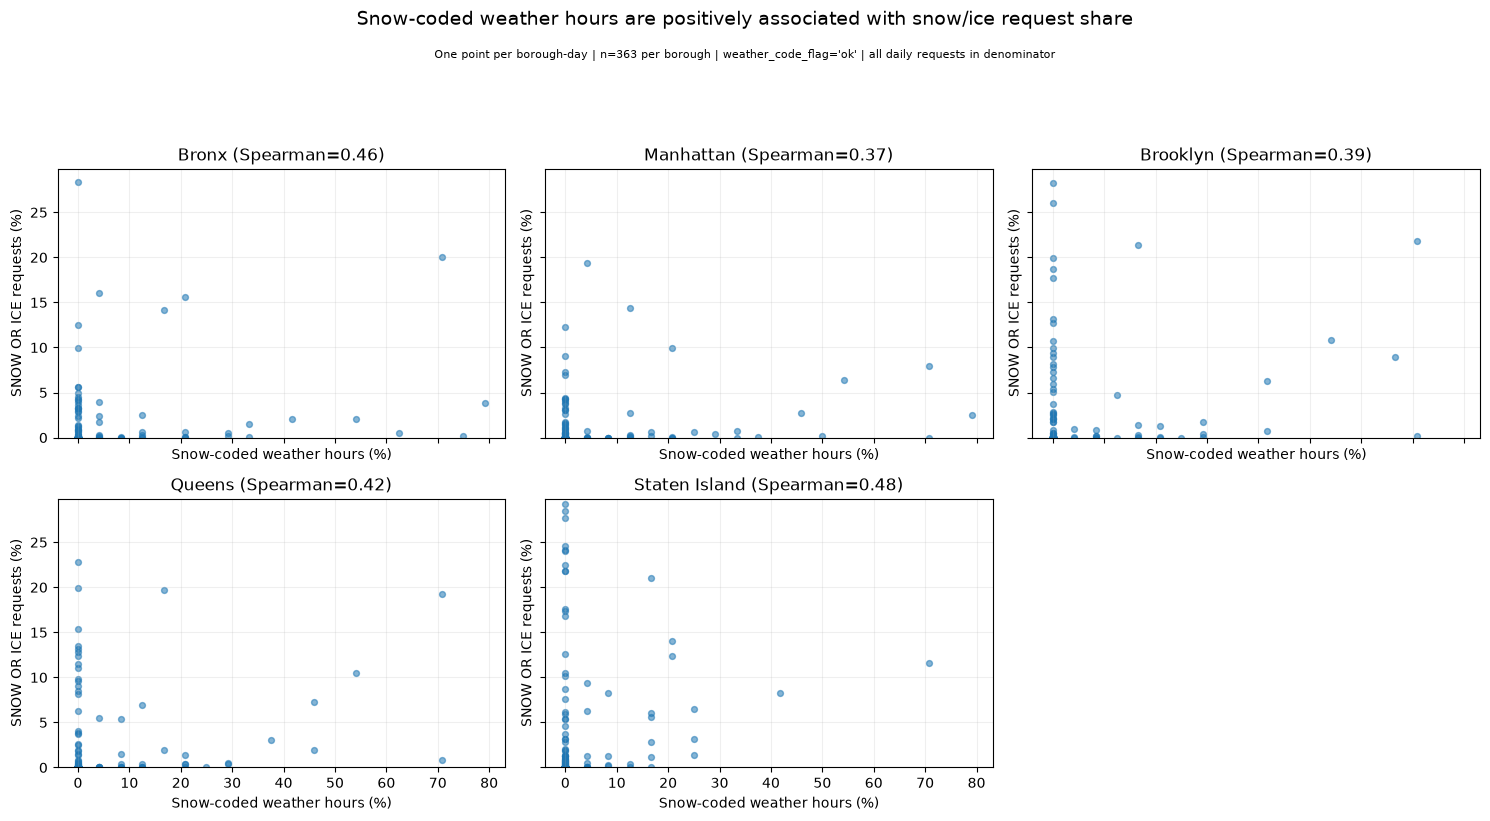

group | n | Pearson | Spearman
ALL | 1815 | 0.2657 | 0.4228
Bronx | 363 | 0.2713 | 0.4582
Manhattan | 363 | 0.1719 | 0.3714
Brooklyn | 363 | 0.2042 | 0.3938
Queens | 363 | 0.3053 | 0.4189
Staten Island | 363 | 0.4438 | 0.4770

Same-day pooled correlation excluding event exposure dates:
n= 1740 Pearson= 0.1891 Spearman= 0.3924


In [37]:
relationship_rows = []
for bid in BOROUGH_IDS:
    for d in EXPECTED_DATES:
        day_key = d.isoformat()
        w = weather_daily[(bid, day_key)]
        expected = expected_local_hours(d)
        valid_code_hours = w["valid_counts"]["weather_code"]
        if valid_code_hours / expected < COVERAGE_THRESHOLD:
            continue
        x = w["snow_hours"] / valid_code_hours if valid_code_hours else None
        y = snow_ice_share_by_borough_day[(bid, day_key)]
        relationship_rows.append({
            "borough_id": bid,
            "borough": BOROUGH_NAMES[bid],
            "date": d,
            "snow_hour_share": x,
            "snow_ice_request_share": y,
        })


def pearson(x_values, y_values):
    n = len(x_values)
    if n < 2:
        return float("nan")
    mx, my = mean(x_values), mean(y_values)
    dx = [x - mx for x in x_values]
    dy = [y - my for y in y_values]
    denom = math.sqrt(sum(v*v for v in dx) * sum(v*v for v in dy))
    return sum(a*b for a, b in zip(dx, dy)) / denom if denom else float("nan")


def average_ranks(values):
    indexed = sorted(enumerate(values), key=lambda item: item[1])
    ranks = [0.0] * len(values)
    i = 0
    while i < len(indexed):
        j = i + 1
        while j < len(indexed) and indexed[j][1] == indexed[i][1]:
            j += 1
        # ranks are one-based; ties receive their average rank.
        rank = ((i + 1) + j) / 2
        for k in range(i, j):
            ranks[indexed[k][0]] = rank
        i = j
    return ranks


def spearman(x_values, y_values):
    return pearson(average_ranks(x_values), average_ranks(y_values))


def correlation_summary(rows):
    x = [r["snow_hour_share"] for r in rows]
    y = [r["snow_ice_request_share"] for r in rows]
    return len(rows), pearson(x, y), spearman(x, y)

# Figure 4 — borough-day scatter, one panel per borough.
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey=True)
axes = axes.flatten()
for ax, bid in zip(axes, BOROUGH_IDS):
    selected = [r for r in relationship_rows if r["borough_id"] == bid]
    ax.scatter(
        [100*r["snow_hour_share"] for r in selected],
        [100*r["snow_ice_request_share"] for r in selected],
        alpha=0.55, s=18,
    )
    _, rp, rs = correlation_summary(selected)
    ax.set_title(f"{BOROUGH_NAMES[bid]} (Spearman={rs:.2f})")
    ax.set_xlabel("Snow-coded weather hours (%)")
    ax.set_ylabel("SNOW OR ICE requests (%)")
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.2)
axes[-1].axis("off")
fig.suptitle("Snow-coded weather hours are positively associated with snow/ice request share", fontsize=14, y=1.02)
fig.text(0.5, 0.96, "One point per borough-day | n=363 per borough | weather_code_flag='ok' | all daily requests in denominator", ha="center", fontsize=8)
fig.tight_layout(rect=[0, 0, 1, 0.91])
fig.savefig(FIGURES_DIR / "snow_ice_share_vs_snow_hours.png", dpi=180, bbox_inches="tight")
plt.show()

print("group | n | Pearson | Spearman")
n, p, s = correlation_summary(relationship_rows)
print(f"ALL | {n} | {p:.4f} | {s:.4f}")
for bid in BOROUGH_IDS:
    selected = [r for r in relationship_rows if r["borough_id"] == bid]
    n, p, s = correlation_summary(selected)
    print(f"{BOROUGH_NAMES[bid]} | {n} | {p:.4f} | {s:.4f}")


def in_storm_window(day):
    return any(start <= day <= end for start, end in STORM_WINDOWS)

nonstorm_same_day = [r for r in relationship_rows if not in_storm_window(r["date"])]
n, p, s = correlation_summary(nonstorm_same_day)
print("\nSame-day pooled correlation excluding event exposure dates:")
print("n=", n, "Pearson=", round(p, 4), "Spearman=", round(s, 4))



In [38]:
# Lagged relationships: snowfall-coded hours on day t versus snow/ice request share on t+lag.
request_share_lookup = {
    (r["borough_id"], r["date"]): r["snow_ice_request_share"]
    for r in relationship_rows
}
exposure_lookup = {
    (r["borough_id"], r["date"]): r["snow_hour_share"]
    for r in relationship_rows
}

lag_pairs = {}
for lag in (0, 1, 2):
    pairs = []
    for bid in BOROUGH_IDS:
        for d in EXPECTED_DATES:
            outcome_day = d + timedelta(days=lag)
            x = exposure_lookup.get((bid, d))
            y = request_share_lookup.get((bid, outcome_day))
            if x is not None and y is not None:
                pairs.append({"borough_id": bid, "exposure_date": d, "outcome_date": outcome_day, "x": x, "y": y})
    lag_pairs[lag] = pairs
    xp = [r["x"] for r in pairs]
    yp = [r["y"] for r in pairs]
    print(f"LAG {lag}: n={len(pairs)} Pearson={pearson(xp, yp):.4f} Spearman={spearman(xp, yp):.4f}")
    if lag > 0:
        for bid in BOROUGH_IDS:
            group = [r for r in pairs if r["borough_id"] == bid]
            gx = [r["x"] for r in group]
            gy = [r["y"] for r in group]
            print(f"  {BOROUGH_NAMES[bid]} n={len(group)} Pearson={pearson(gx, gy):.4f} Spearman={spearman(gx, gy):.4f}")

lag1 = lag_pairs[1]
lag1_exposure_nonstorm = [r for r in lag1 if not in_storm_window(r["exposure_date"])]
lag1_both_nonstorm = [r for r in lag1 if not in_storm_window(r["exposure_date"]) and not in_storm_window(r["outcome_date"])]
for label, selected in [
    ("LAG1 full", lag1),
    ("LAG1 exclude storm exposure dates", lag1_exposure_nonstorm),
    ("LAG1 exclude storm exposure or outcome dates", lag1_both_nonstorm),
]:
    xx, yy = [r["x"] for r in selected], [r["y"] for r in selected]
    print(label, "n=", len(selected), "Pearson=", round(pearson(xx, yy), 4), "Spearman=", round(spearman(xx, yy), 4))

print("\nLAG1 MONTHLY CORRELATIONS BY EXPOSURE MONTH")
by_month = defaultdict(list)
for r in lag1:
    by_month[r["exposure_date"].strftime("%Y-%m")].append(r)
for month in sorted(by_month):
    group = by_month[month]
    xx, yy = [r["x"] for r in group], [r["y"] for r in group]
    ux, uy = len(set(xx)), len(set(yy))
    if ux < 2 or uy < 2:
        print(month, "n=", len(group), "Pearson=NA", "Spearman=NA", "unique_x=", ux, "unique_y=", uy)
    else:
        print(month, "n=", len(group), "Pearson=", round(pearson(xx, yy), 4), "Spearman=", round(spearman(xx, yy), 4), "unique_x=", ux, "unique_y=", uy)

LAG 0: n=1815 Pearson=0.2657 Spearman=0.4228
LAG 1: n=1810 Pearson=0.4960 Spearman=0.4243
  Bronx n=362 Pearson=0.6339 Spearman=0.4304
  Manhattan n=362 Pearson=0.6219 Spearman=0.3486
  Brooklyn n=362 Pearson=0.6460 Spearman=0.4398
  Queens n=362 Pearson=0.6276 Spearman=0.4669
  Staten Island n=362 Pearson=0.5857 Spearman=0.4431
LAG 2: n=1805 Pearson=0.4315 Spearman=0.3823
  Bronx n=361 Pearson=0.5645 Spearman=0.3653
  Manhattan n=361 Pearson=0.5560 Spearman=0.3273
  Brooklyn n=361 Pearson=0.5825 Spearman=0.4001
  Queens n=361 Pearson=0.5111 Spearman=0.4110
  Staten Island n=361 Pearson=0.5137 Spearman=0.4164
LAG1 full n= 1810 Pearson= 0.496 Spearman= 0.4243
LAG1 exclude storm exposure dates n= 1735 Pearson= 0.3774 Spearman= 0.3864
LAG1 exclude storm exposure or outcome dates n= 1725 Pearson= 0.4223 Spearman= 0.3946

LAG1 MONTHLY CORRELATIONS BY EXPOSURE MONTH
2025-10 n= 100 Pearson=NA Spearman=NA unique_x= 1 unique_y= 1
2025-11 n= 150 Pearson= -0.0179 Spearman= 0.0764 unique_x= 6 uniq

In [39]:
# Precipitation sensitivity: daily totals under two explicit flag rules.
precip_daily = {}
for bid in BOROUGH_IDS:
    for d in EXPECTED_DATES:
        item = weather_daily[(bid, d.isoformat())]
        precip_daily[(bid, d)] = {
            "ok_count": item["precip_ok_count"],
            "ok_sum": item["precip_ok_sum"],
            "inclusive_count": item["precip_inclusive_count"],
            "inclusive_sum": item["precip_inclusive_sum"],
            "expected": expected_local_hours(d),
        }

print("\nPRECIPITATION FLAG SENSITIVITY: correlation with same-day SNOW OR ICE share")
print("group | flag_filter | n | Pearson | Spearman")
for filter_name in ("ok", "ok_plus_unusual_high"):
    pairs = []
    for bid in BOROUGH_IDS:
        for d in EXPECTED_DATES:
            w = precip_daily[(bid, d)]
            count = w["ok_count"] if filter_name == "ok" else w["inclusive_count"]
            total = w["ok_sum"] if filter_name == "ok" else w["inclusive_sum"]
            if count == 0:
                continue
            # Keep all dates with at least one usable hour here; the 90% rule is reported separately above.
            pairs.append((bid, total, snow_ice_share_by_borough_day[(bid, d.isoformat())]))
    xx, yy = [p[1] for p in pairs], [p[2] for p in pairs]
    print("ALL", filter_name, len(pairs), round(pearson(xx, yy), 4), round(spearman(xx, yy), 4), sep=" | ")
    for bid in BOROUGH_IDS:
        group = [p for p in pairs if p[0] == bid]
        gx, gy = [p[1] for p in group], [p[2] for p in group]
        print(BOROUGH_NAMES[bid], filter_name, len(group), round(pearson(gx, gy), 4), round(spearman(gx, gy), 4), sep=" | ")


PRECIPITATION FLAG SENSITIVITY: correlation with same-day SNOW OR ICE share
group | flag_filter | n | Pearson | Spearman
ALL | ok | 1815 | 0.0422 | -0.1004
Bronx | ok | 363 | 0.0171 | -0.0654
Manhattan | ok | 363 | -0.0226 | -0.0819
Brooklyn | ok | 363 | -0.0051 | -0.1422
Queens | ok | 363 | 0.0584 | -0.1084
Staten Island | ok | 363 | 0.09 | -0.0966
ALL | ok_plus_unusual_high | 1815 | -0.0006 | -0.1086
Bronx | ok_plus_unusual_high | 363 | -0.0187 | -0.0628
Manhattan | ok_plus_unusual_high | 363 | -0.045 | -0.0906
Brooklyn | ok_plus_unusual_high | 363 | -0.0364 | -0.1549
Queens | ok_plus_unusual_high | 363 | -0.0039 | -0.1201
Staten Island | ok_plus_unusual_high | 363 | 0.0309 | -0.1069


## 7. Local-time, weekday, month, and holiday patterns

Local time is the primary clock for service-request behaviour. UTC is shown only as a comparison using the same unambiguous request subset. Hourly denominators are the number of borough-hour occurrences in the weather coverage table, divided by five to express average requests per citywide clock-hour occurrence. DST days therefore contribute the actual number of occurrences for each local clock hour.

Federal holiday dates use the U.S. Office of Personnel Management schedule ([OPM federal holidays](https://www.opm.gov/policy-data-oversight/pay-leave/federal-holidays/)). This is a calendar indicator only; it does not establish that every NYC service unit was closed.

TIMESTAMP FLAG COUNTS
ambiguous_local_time 796
nonexistent_local_time 1
ok 3947569

UTC AHEAD OF LOCAL CLOCK
4 hours | 2564221
5 hours | 1383348

HOUR | LOCAL ALL | LOCAL OK | UTC OK | LOCAL AVG | UTC AVG
00 | 133324 | 133324 | 182855 | 367.28 | 503.73
01 | 90053 | 89257 | 190126 | 247.40 | 523.76
02 | 61614 | 61613 | 194351 | 170.20 | 535.40
03 | 48435 | 48435 | 168991 | 133.43 | 465.54
04 | 46287 | 46287 | 139616 | 127.51 | 384.62
05 | 55053 | 55053 | 104148 | 151.66 | 286.91
06 | 87111 | 87111 | 69578 | 239.98 | 191.67
07 | 152211 | 152211 | 52000 | 419.31 | 143.25
08 | 207842 | 207842 | 46977 | 572.57 | 129.41
09 | 235075 | 235075 | 51908 | 647.59 | 143.00
10 | 238717 | 238717 | 76583 | 657.62 | 210.97
11 | 234958 | 234958 | 126413 | 647.27 | 348.25
12 | 226190 | 226190 | 189622 | 623.11 | 522.37
13 | 218342 | 218342 | 226480 | 601.49 | 623.91
14 | 215058 | 215058 | 237923 | 592.45 | 655.44
15 | 210816 | 210816 | 236270 | 580.76 | 650.88
16 | 202930 | 202930 | 227973 | 559.04 | 628

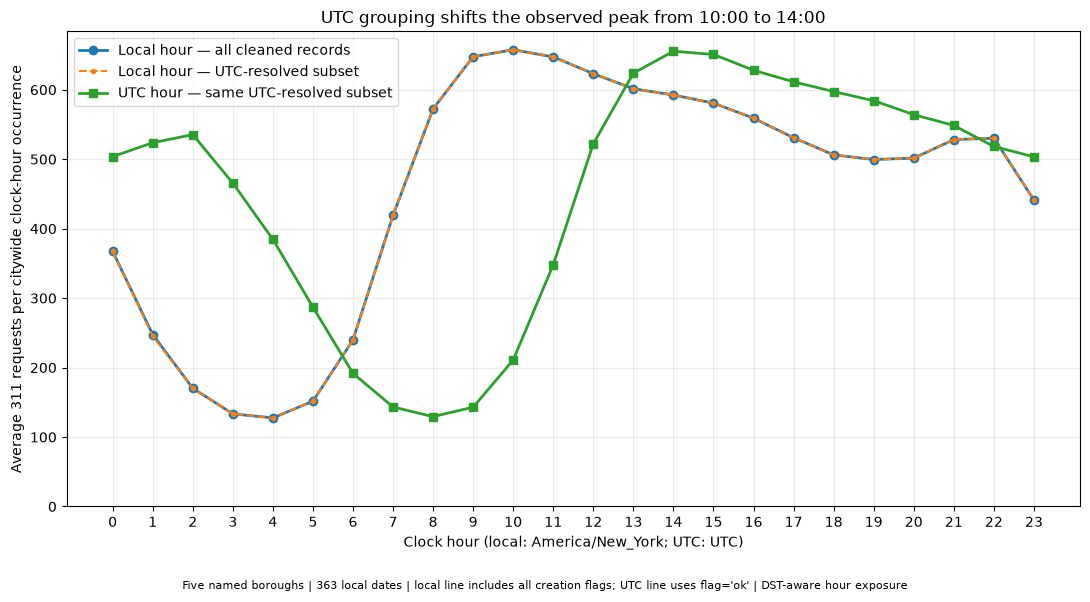

In [40]:
# Timestamp flags and local-vs-UTC counts; same analysis window and borough filter.
flag_rows = CON.execute(
    """
    SELECT created_at_utc_flag, COUNT(*) AS n
    FROM service_requests_clean
    WHERE borough_id IN (?, ?, ?, ?, ?)
      AND created_local_date >= ? AND created_local_date <= ?
    GROUP BY created_at_utc_flag
    ORDER BY created_at_utc_flag
    """,
    (*BOROUGH_IDS, START_DATE.isoformat(), END_DATE.isoformat()),
).fetchall()
print("TIMESTAMP FLAG COUNTS")
for r in flag_rows:
    print(r["created_at_utc_flag"], r["n"])

local_all_rows = CON.execute(
    """
    SELECT created_local_hour AS hour, COUNT(*) AS n
    FROM service_requests_clean
    WHERE borough_id IN (?, ?, ?, ?, ?)
      AND created_local_date >= ? AND created_local_date <= ?
    GROUP BY created_local_hour
    ORDER BY created_local_hour
    """,
    (*BOROUGH_IDS, START_DATE.isoformat(), END_DATE.isoformat()),
).fetchall()
local_ok_rows = CON.execute(
    """
    SELECT created_local_hour AS hour, COUNT(*) AS n
    FROM service_requests_clean
    WHERE borough_id IN (?, ?, ?, ?, ?)
      AND created_local_date >= ? AND created_local_date <= ?
      AND created_at_utc_flag = 'ok' AND created_at_utc IS NOT NULL
    GROUP BY created_local_hour
    ORDER BY created_local_hour
    """,
    (*BOROUGH_IDS, START_DATE.isoformat(), END_DATE.isoformat()),
).fetchall()
utc_ok_rows = CON.execute(
    """
    SELECT CAST(strftime('%H', created_at_utc) AS INTEGER) AS hour,
           COUNT(*) AS n
    FROM service_requests_clean
    WHERE borough_id IN (?, ?, ?, ?, ?)
      AND created_local_date >= ? AND created_local_date <= ?
      AND created_at_utc_flag = 'ok' AND created_at_utc IS NOT NULL
    GROUP BY CAST(strftime('%H', created_at_utc) AS INTEGER)
    ORDER BY hour
    """,
    (*BOROUGH_IDS, START_DATE.isoformat(), END_DATE.isoformat()),
).fetchall()

local_all = {h: 0 for h in range(24)}
local_ok = {h: 0 for h in range(24)}
utc_ok = {h: 0 for h in range(24)}
for r in local_all_rows: local_all[int(r["hour"])] = int(r["n"])
for r in local_ok_rows: local_ok[int(r["hour"])] = int(r["n"])
for r in utc_ok_rows: utc_ok[int(r["hour"])] = int(r["n"])

local_exposure = {h: weather_local_exposure[h] / len(BOROUGH_IDS) for h in range(24)}
utc_exposure = {h: weather_utc_exposure[h] / len(BOROUGH_IDS) for h in range(24)}
local_rate_all = {h: local_all[h] / local_exposure[h] for h in range(24)}
local_rate_ok = {h: local_ok[h] / local_exposure[h] for h in range(24)}
utc_rate_ok = {h: utc_ok[h] / utc_exposure[h] for h in range(24)}
local_peak = max(local_rate_all, key=local_rate_all.get)
utc_peak = max(utc_rate_ok, key=utc_rate_ok.get)
local_trough = min(local_rate_all, key=local_rate_all.get)
utc_trough = min(utc_rate_ok, key=utc_rate_ok.get)

print("\nUTC AHEAD OF LOCAL CLOCK")
offset_rows = CON.execute(
    """
    SELECT (CAST(strftime('%H', created_at_utc) AS INTEGER)
            - created_local_hour + 24) % 24 AS offset_hours,
           COUNT(*) AS n
    FROM service_requests_clean
    WHERE borough_id IN (?, ?, ?, ?, ?)
      AND created_local_date >= ? AND created_local_date <= ?
      AND created_at_utc_flag = 'ok' AND created_at_utc IS NOT NULL
    GROUP BY offset_hours ORDER BY offset_hours
    """,
    (*BOROUGH_IDS, START_DATE.isoformat(), END_DATE.isoformat()),
).fetchall()
for r in offset_rows:
    print(r["offset_hours"], "hours |", r["n"])

print("\nHOUR | LOCAL ALL | LOCAL OK | UTC OK | LOCAL AVG | UTC AVG")
for h in range(24):
    print(f"{h:02d} | {local_all[h]} | {local_ok[h]} | {utc_ok[h]} | {local_rate_all[h]:.2f} | {utc_rate_ok[h]:.2f}")
print("Local peak/trough:", f"{local_peak:02d}:00", f"{local_trough:02d}:00")
print("UTC peak/trough:", f"{utc_peak:02d}:00", f"{utc_trough:02d}:00")

# Figure 5 — local-vs-UTC hourly profile.
fig, ax = plt.subplots(figsize=(11, 6))
hours = list(range(24))
ax.plot(hours, [local_rate_all[h] for h in hours], marker="o", linewidth=2, label="Local hour — all cleaned records")
ax.plot(hours, [local_rate_ok[h] for h in hours], marker=".", linestyle="--", label="Local hour — UTC-resolved subset")
ax.plot(hours, [utc_rate_ok[h] for h in hours], marker="s", linewidth=2, label="UTC hour — same UTC-resolved subset")
ax.set_title(f"UTC grouping shifts the observed peak from {local_peak:02d}:00 to {utc_peak:02d}:00")
ax.set_xlabel("Clock hour (local: America/New_York; UTC: UTC)")
ax.set_ylabel("Average 311 requests per citywide clock-hour occurrence")
ax.set_xticks(hours)
ax.set_ylim(bottom=0)
ax.grid(alpha=0.25)
ax.legend()
fig.text(0.5, 0.01, "Five named boroughs | 363 local dates | local line includes all creation flags; UTC line uses flag='ok' | DST-aware hour exposure", ha="center", fontsize=8)
fig.tight_layout(rect=[0, 0.05, 1, 1])
fig.savefig(FIGURES_DIR / "hourly_profile_local_vs_utc.png", dpi=180, bbox_inches="tight")
plt.show()

WEEKDAY | n | mean | median | min | max
Monday | 52 | 11623.06 | 11321.50 | 9175 | 16369
Tuesday | 52 | 11674.71 | 11418.00 | 8351 | 22796
Wednesday | 52 | 11053.27 | 10924.50 | 7777 | 16975
Thursday | 52 | 10888.58 | 10832.00 | 6214 | 15351
Friday | 52 | 11005.13 | 10752.00 | 8507 | 15443
Saturday | 51 | 9829.76 | 9766.00 | 7833 | 13142
Sunday | 52 | 10044.63 | 9734.50 | 7326 | 15675

MONTH | observed_days | calendar_days | coverage_pct | daily_mean | daily_median | included
2025-10 | 20 | 31 | 64.52 | 11211.50 | 11312.50 | NO
2025-11 | 30 | 30 | 100.00 | 10156.97 | 10133.00 | YES
2025-12 | 31 | 31 | 100.00 | 10705.58 | 10491.00 | YES
2026-01 | 31 | 31 | 100.00 | 11235.29 | 10516.00 | YES
2026-02 | 28 | 28 | 100.00 | 11945.43 | 11088.00 | YES
2026-03 | 31 | 31 | 100.00 | 11032.19 | 11221.00 | YES
2026-04 | 30 | 30 | 100.00 | 10059.63 | 9994.00 | YES
2026-05 | 31 | 31 | 100.00 | 10696.23 | 10858.00 | YES
2026-06 | 30 | 30 | 100.00 | 11147.57 | 11211.00 | YES
2026-07 | 31 | 31 | 100.00 

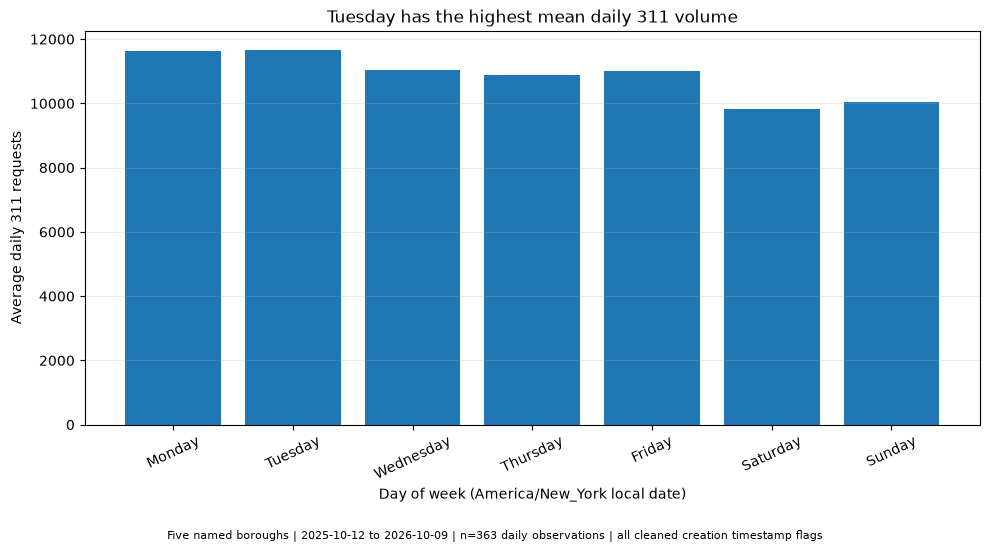

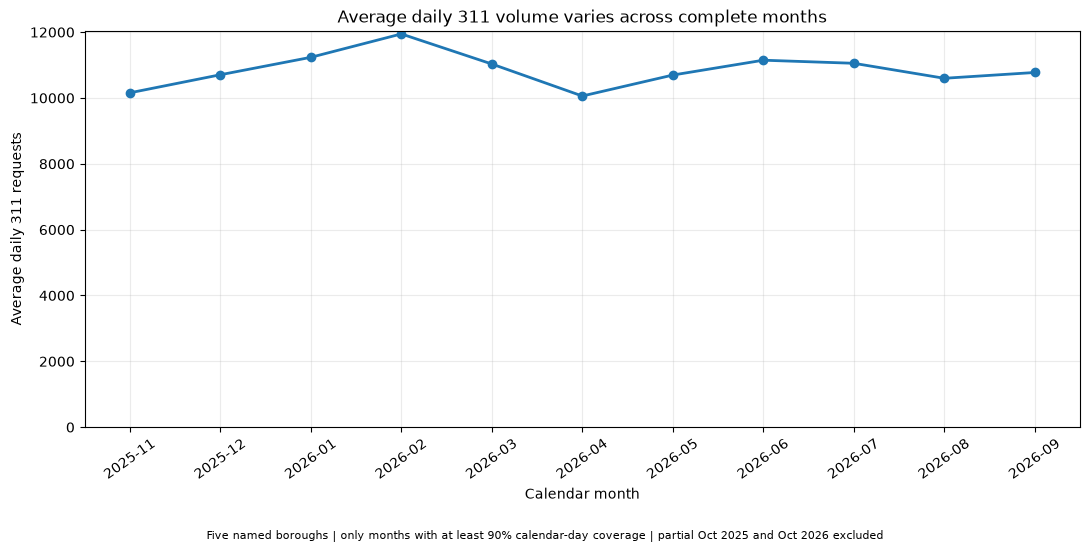

In [41]:
# Weekday and monthly profiles from the same citywide daily series.
WEEKDAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_daily = {name: [] for name in WEEKDAYS}
monthly_daily = defaultdict(list)
for d, value in zip(EXPECTED_DATES, citywide_daily):
    weekday_daily[WEEKDAYS[d.weekday()]].append(value)
    monthly_daily[d.strftime("%Y-%m")].append((d, value))

print("WEEKDAY | n | mean | median | min | max")
for name in WEEKDAYS:
    vals = weekday_daily[name]
    print(name, len(vals), f"{mean(vals):.2f}", f"{median(vals):.2f}", min(vals), max(vals), sep=" | ")

monthly_profile = []
print("\nMONTH | observed_days | calendar_days | coverage_pct | daily_mean | daily_median | included")
for month in sorted(monthly_daily):
    year, month_num = map(int, month.split("-"))
    calendar_days = (date(year + (month_num == 12), (month_num % 12) + 1, 1) - date(year, month_num, 1)).days
    vals = [v for _, v in monthly_daily[month]]
    coverage = len(vals) / calendar_days
    included = coverage >= COVERAGE_THRESHOLD
    print(month, len(vals), calendar_days, f"{coverage*100:.2f}", f"{mean(vals):.2f}", f"{median(vals):.2f}", "YES" if included else "NO", sep=" | ")
    if included:
        monthly_profile.append((month, mean(vals), median(vals), len(vals)))

weekday_means = [mean(weekday_daily[name]) for name in WEEKDAYS]
peak_weekday = WEEKDAYS[weekday_means.index(max(weekday_means))]
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.bar(WEEKDAYS, weekday_means)
ax.set_title(f"{peak_weekday} has the highest mean daily 311 volume")
ax.set_xlabel("Day of week (America/New_York local date)")
ax.set_ylabel("Average daily 311 requests")
ax.set_ylim(bottom=0)
ax.tick_params(axis="x", rotation=25)
ax.grid(axis="y", alpha=0.25)
fig.text(0.5, 0.01, f"Five named boroughs | {START_DATE} to {END_DATE} | n=363 daily observations | all cleaned creation timestamp flags", ha="center", fontsize=8)
fig.tight_layout(rect=[0, 0.05, 1, 1])
fig.savefig(FIGURES_DIR / "weekday_profile.png", dpi=180, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(11, 5.5))
month_labels = [r[0] for r in monthly_profile]
month_means = [r[1] for r in monthly_profile]
ax.plot(month_labels, month_means, marker="o", linewidth=2)
ax.set_title("Average daily 311 volume varies across complete months")
ax.set_xlabel("Calendar month")
ax.set_ylabel("Average daily 311 requests")
ax.set_ylim(bottom=0)
ax.tick_params(axis="x", rotation=35)
ax.grid(alpha=0.25)
fig.text(0.5, 0.01, "Five named boroughs | only months with at least 90% calendar-day coverage | partial Oct 2025 and Oct 2026 excluded", ha="center", fontsize=8)
fig.tight_layout(rect=[0, 0.05, 1, 1])
fig.savefig(FIGURES_DIR / "monthly_profile.png", dpi=180, bbox_inches="tight")
plt.show()

In [42]:
# Federal holidays: a fixed calendar indicator, not a claim about NYC agency closures.
FEDERAL_HOLIDAYS = {
    "2025-10-13": "Columbus Day",
    "2025-11-11": "Veterans Day",
    "2025-11-27": "Thanksgiving Day",
    "2025-12-25": "Christmas Day",
    "2026-01-01": "New Year's Day",
    "2026-01-19": "Birthday of Martin Luther King, Jr.",
    "2026-02-16": "Washington's Birthday",
    "2026-05-25": "Memorial Day",
    "2026-06-19": "Juneteenth",
    "2026-07-03": "Independence Day (observed)",
    "2026-09-07": "Labor Day",
}
citywide_by_date = {d.isoformat(): value for d, value in zip(EXPECTED_DATES, citywide_daily)}
holiday_values = [(ds, name, citywide_by_date[ds]) for ds, name in FEDERAL_HOLIDAYS.items() if ds in citywide_by_date]
nonholiday_weekday_values = [
    value for d, value in zip(EXPECTED_DATES, citywide_daily)
    if d.weekday() < 5 and d.isoformat() not in FEDERAL_HOLIDAYS
]
print("FEDERAL HOLIDAY | DATE | DAILY REQUESTS")
for ds, name, value in sorted(holiday_values):
    print(name, ds, value, sep=" | ")
print("Holiday weekdays:", len(holiday_values), "mean:", round(mean(v for _, _, v in holiday_values), 2), "median:", median(v for _, _, v in holiday_values))
print("Non-holiday weekdays:", len(nonholiday_weekday_values), "mean:", round(mean(nonholiday_weekday_values), 2), "median:", median(nonholiday_weekday_values))
print("Mean difference (holiday minus non-holiday weekdays):", round(mean(v for _, _, v in holiday_values) - mean(nonholiday_weekday_values), 2))

FEDERAL HOLIDAY | DATE | DAILY REQUESTS
Columbus Day | 2025-10-13 | 11263
Veterans Day | 2025-11-11 | 12166
Thanksgiving Day | 2025-11-27 | 8143
Christmas Day | 2025-12-25 | 6214
New Year's Day | 2026-01-01 | 8288
Birthday of Martin Luther King, Jr. | 2026-01-19 | 9686
Washington's Birthday | 2026-02-16 | 9175
Memorial Day | 2026-05-25 | 10064
Juneteenth | 2026-06-19 | 10225
Independence Day (observed) | 2026-07-03 | 13062
Labor Day | 2026-09-07 | 10615
Holiday weekdays: 11 mean: 9900.09 median: 10064
Non-holiday weekdays: 249 mean: 11308.54 median: 11051
Mean difference (holiday minus non-holiday weekdays): -1408.45


## 8. Main comparison and uncertainty: weekday versus weekend

**Primary comparison:** mean daily 311 volume on weekdays (Monday–Friday) versus weekends (Saturday–Sunday). The full analysis window contains 260 weekdays and 103 weekend days. For uncertainty, only 51 complete Monday–Sunday calendar weeks are resampled as blocks, preserving within-week structure. A percentile interval is computed from 20,000 bootstrap repetitions using seed `20261115`.

A monthly composition check excludes months with less than 90% calendar-day coverage, then checks whether the weekday–weekend direction is consistent within each of the 11 eligible months. The comparison was selected during exploration (post hoc); the analysis log records seven weekday summaries plus 13 monthly summaries (approximately 20 temporal summaries examined), not a pre-registered single test.

In [43]:
weekday_all = [v for d, v in zip(EXPECTED_DATES, citywide_daily) if d.weekday() < 5]
weekend_all = [v for d, v in zip(EXPECTED_DATES, citywide_daily) if d.weekday() >= 5]
print("FULL PERIOD")
print("Weekday n/mean/median:", len(weekday_all), round(mean(weekday_all), 2), median(weekday_all))
print("Weekend n/mean/median:", len(weekend_all), round(mean(weekend_all), 2), median(weekend_all))
print("Difference weekday - weekend:", round(mean(weekday_all) - mean(weekend_all), 2))

# Construct complete Monday-Sunday blocks; edge partial weeks are excluded from bootstrap only.
by_date = {d: v for d, v in zip(EXPECTED_DATES, citywide_daily)}
complete_week_starts = []
for d in EXPECTED_DATES:
    if d.weekday() == 0 and all((d + timedelta(days=i)) in by_date for i in range(7)):
        complete_week_starts.append(d)
complete_week_blocks = []
for monday in complete_week_starts:
    week = [by_date[monday + timedelta(days=i)] for i in range(7)]
    complete_week_blocks.append({"weekday": week[:5], "weekend": week[5:]})
assert len(complete_week_blocks) == 51

observed_weekday = [v for block in complete_week_blocks for v in block["weekday"]]
observed_weekend = [v for block in complete_week_blocks for v in block["weekend"]]
observed_difference = mean(observed_weekday) - mean(observed_weekend)

rng = random.Random(BOOTSTRAP_SEED)
bootstrap_differences = []
for _ in range(BOOTSTRAP_REPETITIONS):
    sampled = [complete_week_blocks[i] for i in rng.choices(range(len(complete_week_blocks)), k=len(complete_week_blocks))]
    sampled_weekday = [v for block in sampled for v in block["weekday"]]
    sampled_weekend = [v for block in sampled for v in block["weekend"]]
    bootstrap_differences.append(mean(sampled_weekday) - mean(sampled_weekend))

def linear_percentile(values, p):
    ordered = sorted(values)
    pos = (len(ordered) - 1) * p
    lo = math.floor(pos)
    hi = math.ceil(pos)
    if lo == hi:
        return ordered[lo]
    fraction = pos - lo
    return ordered[lo] * (1 - fraction) + ordered[hi] * fraction

ci_low = linear_percentile(bootstrap_differences, 0.025)
ci_high = linear_percentile(bootstrap_differences, 0.975)
print("\nCOMPLETE-WEEK BLOCK BOOTSTRAP")
print("Complete weeks:", len(complete_week_blocks))
print("Bootstrap weekday/weekend n:", len(observed_weekday), len(observed_weekend))
print("Replicates and seed:", BOOTSTRAP_REPETITIONS, BOOTSTRAP_SEED)
print("Block-bootstrap weekday mean:", round(mean(observed_weekday), 2))
print("Block-bootstrap weekend mean:", round(mean(observed_weekend), 2))
print("Difference:", round(observed_difference, 2))
print("95% percentile bootstrap CI:", (round(ci_low, 2), round(ci_high, 2)))

print("\nMONTHLY COMPOSITION CHECK")
monthly_diffs = []
print("month | weekday_n | weekday_mean | weekend_n | weekend_mean | difference")
for month, _, _, _ in monthly_profile:
    subset = [(d, v) for d, v in zip(EXPECTED_DATES, citywide_daily) if d.strftime("%Y-%m") == month]
    wd = [v for d, v in subset if d.weekday() < 5]
    we = [v for d, v in subset if d.weekday() >= 5]
    diff = mean(wd) - mean(we)
    monthly_diffs.append((month, diff))
    print(month, len(wd), f"{mean(wd):.2f}", len(we), f"{mean(we):.2f}", f"{diff:.2f}", sep=" | ")
print("Eligible months:", len(monthly_diffs))
print("Months weekday > weekend:", sum(diff > 0 for _, diff in monthly_diffs))
print("Months weekday < weekend:", sum(diff < 0 for _, diff in monthly_diffs))
print("Months tied:", sum(diff == 0 for _, diff in monthly_diffs))
print("Equal-month-weighted mean difference:", round(mean(diff for _, diff in monthly_diffs), 2))

FULL PERIOD
Weekday n/mean/median: 260 11248.95 11037.0
Weekend n/mean/median: 103 9938.24 9738
Difference weekday - weekend: 1310.71

COMPLETE-WEEK BLOCK BOOTSTRAP
Complete weeks: 51
Bootstrap weekday/weekend n: 255 102
Replicates and seed: 20000 20261115
Block-bootstrap weekday mean: 11245.89
Block-bootstrap weekend mean: 9937.74
Difference: 1308.16
95% percentile bootstrap CI: (966.42, 1658.44)

MONTHLY COMPOSITION CHECK
month | weekday_n | weekday_mean | weekend_n | weekend_mean | difference
2025-11 | 20 | 10585.75 | 10 | 9299.40 | 1286.35
2025-12 | 23 | 11101.22 | 8 | 9568.12 | 1533.09
2026-01 | 22 | 11871.50 | 9 | 9680.11 | 2191.39
2026-02 | 20 | 12378.60 | 8 | 10862.50 | 1516.10
2026-03 | 22 | 11529.23 | 9 | 9817.22 | 1712.01
2026-04 | 22 | 10499.68 | 8 | 8849.50 | 1650.18
2026-05 | 21 | 11166.81 | 10 | 9708.00 | 1458.81
2026-06 | 22 | 11251.95 | 8 | 10860.50 | 391.45
2026-07 | 23 | 11165.96 | 8 | 10732.00 | 433.96
2026-08 | 21 | 10878.71 | 10 | 10009.20 | 869.51
2026-09 | 22 | 

## 9. Findings, interpretation, and hand-off

The notebook results should be read as exploratory evidence. The most pronounced patterns are: (1) a right-skewed citywide daily-volume distribution with event-driven upper-tail days; (2) stable borough ranking by mean and median, but very different scales and tails; (3) a local daytime request peak that would be mislabelled if UTC were treated as local time; (4) a positive same-day and lagged association between snow-coded weather hours and the `SNOW OR ICE` request share; and (5) higher weekday than weekend request volume, with the direction reproduced in each eligible month.

Before modelling, retain storm days and unusual but plausible measurements, document the precipitation flag sensitivity, use local time for behavioural variables, and account for seasonality, temporal dependence, delayed reporting, borough differences, and the absence of population denominators.

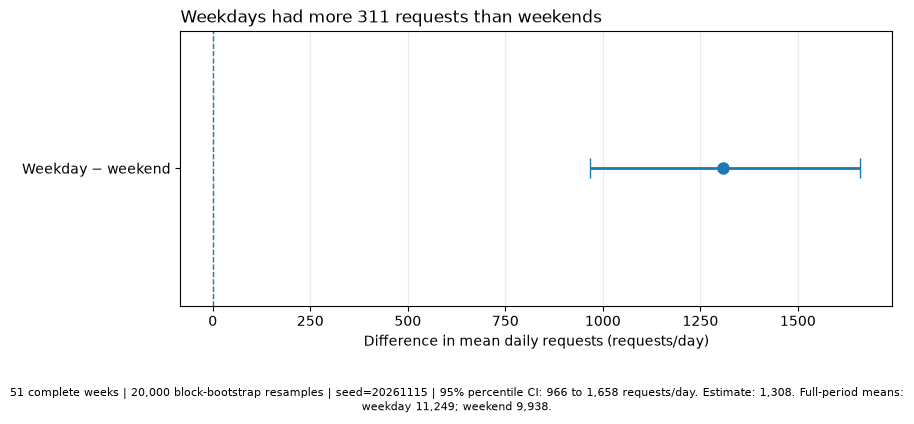

In [44]:
# Figure 8 — weekday versus weekend difference with a 95% block-bootstrap CI.
# Uses the results calculated from the database in the preceding comparison cell.

assert len(complete_week_blocks) == 51
assert ci_low <= observed_difference <= ci_high

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.axvline(0, linestyle="--", linewidth=1)
ax.errorbar(
    [observed_difference],
    [0],
    xerr=[[observed_difference - ci_low], [ci_high - observed_difference]],
    fmt="o",
    capsize=7,
    linewidth=2,
    markersize=8,
)
ax.set_yticks([0], ["Weekday − weekend"])
ax.set_xlabel("Difference in mean daily requests (requests/day)")
ax.set_title("Weekdays had more 311 requests than weekends", loc="left")
ax.grid(axis="x", alpha=0.25)

caption = (
    f"{len(complete_week_blocks)} complete weeks | "
    f"{BOOTSTRAP_REPETITIONS:,} block-bootstrap resamples | "
    f"seed={BOOTSTRAP_SEED} | 95% percentile CI: "
    f"{ci_low:,.0f} to {ci_high:,.0f} requests/day. "
    f"Estimate: {observed_difference:,.0f}. "
    f"Full-period means: weekday {mean(weekday_all):,.0f}; "
    f"weekend {mean(weekend_all):,.0f}."
)
fig.text(0.5, 0.01, caption, ha="center", fontsize=8, wrap=True)
fig.tight_layout(rect=[0, 0.12, 1, 1])
fig.savefig(FIGURES_DIR / "weekday_weekend_difference_bootstrap.png",
            dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)


In [45]:
# Final validation: query-only remains enabled and the database file metadata is unchanged.
print("Figures written:")
for name in [
    "daily_volume_histogram_sensitivity.png",
    "daily_volume_histogram_by_borough.png",
    "daily_volume_ecdf_by_borough.png",
    "snow_ice_share_vs_snow_hours.png",
    "hourly_profile_local_vs_utc.png",
    "weekday_profile.png",
    "monthly_profile.png",
    "weekday_weekend_difference_bootstrap.png",
]:
    path = FIGURES_DIR / name
    print(path.relative_to(PROJECT_ROOT), "exists=", path.is_file())
    assert path.is_file(), f"Expected figure was not created: {path}"

DB_STAT_AFTER = (DB_PATH.stat().st_size, DB_PATH.stat().st_mtime_ns)
print("\nDatabase query_only:", CON.execute("PRAGMA query_only").fetchone()[0])
print("Database file size unchanged:", DB_STAT_BEFORE[0] == DB_STAT_AFTER[0])
print("Database mtime unchanged:", DB_STAT_BEFORE[1] == DB_STAT_AFTER[1])
assert DB_STAT_BEFORE == DB_STAT_AFTER, "Database file metadata changed during this read-only notebook."
CON.close()
print("RESULT: notebook analysis completed; SQLite connection closed.")

Figures written:
figures/daily_volume_histogram_sensitivity.png exists= True
figures/daily_volume_histogram_by_borough.png exists= True
figures/daily_volume_ecdf_by_borough.png exists= True
figures/snow_ice_share_vs_snow_hours.png exists= True
figures/hourly_profile_local_vs_utc.png exists= True
figures/weekday_profile.png exists= True
figures/monthly_profile.png exists= True
figures/weekday_weekend_difference_bootstrap.png exists= True

Database query_only: 1
Database file size unchanged: True
Database mtime unchanged: True
RESULT: notebook analysis completed; SQLite connection closed.
